# TCC: Previsão de Inadimplência em Concessão de Crédito
**Metodologia:** CRISP-DM

---

## Fases 4 e 5: Modelagem Preditiva e Avaliação (*Modeling & Evaluation*)

Este *notebook* dá continuidade à metodologia CRISP-DM. Após o entendimento e a preparação matemática dos dados (Fases 1, 2 e 3) realizados nos arquivos anteriores, o foco agora é treinar os algoritmos de *Machine Learning* e avaliar o seu desempenho.

Com base na fundamentação do projeto, aplicaremos o **Aprendizado Sensível ao Custo** (*Cost-Sensitive Learning*) para lidar com o desbalanceamento da classe alvo (80% adimplentes / 20% inadimplentes). Iniciaremos com a Regressão Logística para estabelecer a nossa linha de base (*baseline*) e avançaremos para os métodos baseados em árvores (Random Forest e XGBoost).

---

## 1. Importação de Bibliotecas e Carregamento dos Dados
Nesta etapa inicial, carregamos as ferramentas matemáticas do Scikit-Learn e as matrizes otimizadas em Parquet (Treino, Validação e Teste) geradas ao final da etapa de Preparação de Dados.

In [5]:
# Importacao das bibliotecas de modelagem preditiva e metricas
import polars as pl
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    average_precision_score # PR-AUC
)

# Importacao das bibliotecas visuais para a Matriz de Confusao
import matplotlib.pyplot as plt
import seaborn as sns

# FUNCAO PADRONIZADA DE AVALIACAO
def evaluate_classification(y_true, y_pred, y_pred_proba, model_name="Modelo"):
    """Calcula, exibe e retorna as metricas de classificacao."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    pr_auc = average_precision_score(y_true, y_pred_proba)

    print(f"--- Resultados: {model_name} ---")
    print(f"PR-AUC  : {pr_auc:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Recall  : {rec:.4f}")
    print(f"Precisao: {prec:.4f}")
    print(f"Acuracia: {acc:.4f}\n")
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Adimplente (0)', 'Inadimplente (1)'], 
                yticklabels=['Adimplente (0)', 'Inadimplente (1)'])
    plt.ylabel('Classe Real (Actual value)')
    plt.xlabel('Classe Predita (Predicted value)')
    plt.title(f'Matriz de Confusao - {model_name}')
    plt.show()

    return {
        "Modelo": model_name,
        "PR-AUC": pr_auc,
        "F1-score": f1,
        "Recall": rec,
        "Precisao": prec,
        "Acuracia": acc,
    }

# PREPARACAO DOS DADOS
# Carregamento otimizado dos ficheiros particionados
df_train = pl.read_parquet('DataSet_Loan/df_treino.parquet')
df_val = pl.read_parquet('DataSet_Loan/df_val.parquet')
df_test = pl.read_parquet('DataSet_Loan/df_teste.parquet')

# Separacao entre variaveis preditivas (X) e a variavel alvo (y)
X_train = df_train.drop('target').to_pandas()
y_train = df_train.select('target').to_pandas().squeeze()

X_val = df_val.drop('target').to_pandas()
y_val = df_val.select('target').to_pandas().squeeze()

X_test = df_test.drop('target').to_pandas()
y_test = df_test.select('target').to_pandas().squeeze()

## 2. Regressão Logística (*Baseline*)

A **Regressão Logística** é utilizada como modelo de linha de base (*baseline*). Por ser um algoritmo estatístico de natureza linear, seu objetivo é estabelecer um referencial de desempenho para comparação com os modelos de *ensemble learning*.


### 2.1. Treinamento do Modelo

Nesta etapa, o modelo é treinado com o conjunto de treino e avaliado no conjunto de validação. Como a variável alvo apresenta desbalanceamento, utiliza-se `class_weight='balanced'`. As variáveis são padronizadas com `StandardScaler`, pois a Regressão Logística é sensível à escala dos atributos.

--- Resultados: Regressao Logistica - Baseline ---
PR-AUC  : 0.3743
F1-score: 0.4268
Recall  : 0.6525
Precisao: 0.3171
Acuracia: 0.6460



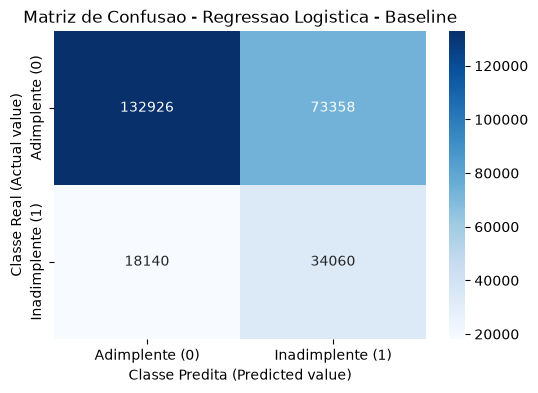

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42, max_iter=2000)
)

log_reg.fit(X_train, y_train)

y_pred_val_lr = log_reg.predict(X_val)
y_pred_proba_val_lr = log_reg.predict_proba(X_val)[:, 1]

baseline_lr_results = evaluate_classification(
    y_val,
    y_pred_val_lr, 
    y_pred_proba_val_lr,
    model_name="Regressao Logistica - Baseline"
)

## 3. Random Forest

Avançando para os modelos de *ensemble learning*, a segunda abordagem avaliada é o algoritmo **Random Forest**. Por ser um método baseado na construção de múltiplas árvores de decisão com menor correlação entre si, utilizando a estratégia de *bagging*, esse modelo possui alta capacidade para mapear relações não lineares complexas entre os atributos dos clientes, algo que o modelo linear de *baseline* não consegue realizar nativamente.

Para manter a coerência metodológica e lidar com o desbalanceamento das classes, a técnica de **Cost-Sensitive Learning** é preservada por meio do parâmetro `class_weight='balanced'`. Além disso, para mitigar o risco de sobreajuste (*overfitting*) inerente aos modelos baseados em árvores, a profundidade máxima das árvores (`max_depth`) é inicialmente controlada.

Ao contrário da Regressão Logística, algoritmos baseados em árvores não dependem da escala das variáveis. Por isso, o Random Forest dispensa o uso de padronizadores como o `StandardScaler`.

### 3.1. Treinamento do Modelo

Nesta etapa, é treinada uma configuração inicial do Random Forest utilizando o conjunto de treino. O modelo é avaliado no conjunto de validação, que será utilizado como referência para as etapas posteriores de ajuste.

--- Resultados: Random Forest - Baseline ---
PR-AUC  : 0.3802
F1-score: 0.4281
Recall  : 0.6725
Precisao: 0.3139
Acuracia: 0.6371



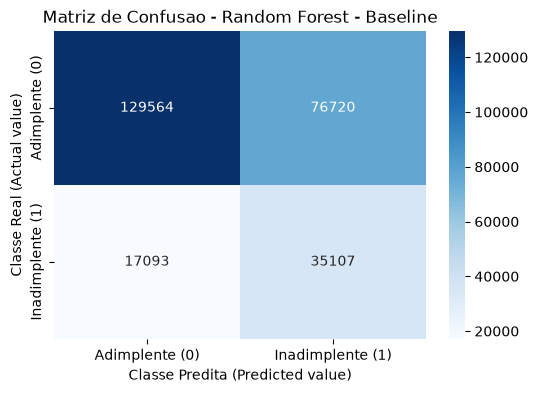

In [10]:
from sklearn.ensemble import RandomForestClassifier

# max_depth=10 atua como controle inicial contra overfitting (sobreajuste)
# n_jobs=-1 paraleliza o processamento para maior velocidade
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Treinamento
rf_model.fit(X_train, y_train)

# Geração das predições e probabilidades no conjunto de validação
y_pred_val_rf = rf_model.predict(X_val)
y_pred_proba_val_rf = rf_model.predict_proba(X_val)[:, 1]

# Registro automatico dos parametros do baseline
baseline_rf_params = {
    parametro: rf_model.get_params()[parametro]
    for parametro in [
        "n_estimators", 
        "max_depth", 
        "class_weight", 
        "random_state"
    ]
}

baseline_rf_results = evaluate_classification(
    y_val,
    y_pred_val_rf,
    y_pred_proba_val_rf,
    model_name="Random Forest - Baseline"
)

### 3.2. Ajuste de Hiperparâmetros

Após a avaliação da configuração inicial, os principais hiperparâmetros do Random Forest serão ajustados de forma automatizada utilizando os conjuntos de treino e validação. Serão avaliados diferentes valores de `n_estimators`, `max_depth` e `min_samples_leaf`, que controlam, respectivamente, a quantidade de árvores, a complexidade máxima de cada árvore e o número mínimo de observações em cada folha.

A escolha da configuração final será orientada principalmente pelas métricas PR-AUC, Recall e F1-score, considerando o objetivo de identificar clientes com maior risco de inadimplência. O conjunto de teste Out-of-Time não participa dessa etapa.

In [14]:
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, f1_score, recall_score

param_grid_rf = {
    "n_estimators": [200, 500],
    "max_depth": [10, 12],
    "min_samples_leaf": [5, 10],
}

rf_tuning_results = []

for params in ParameterGrid(param_grid_rf):
    model = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    rf_tuning_results.append({
        **params,
        "PR-AUC": average_precision_score(y_val, y_proba),
        "F1-score": f1_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
    })

rf_tuning_results_df = (
    pd.DataFrame(rf_tuning_results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

rf_tuning_results_df

,max_depth,min_samples_leaf,n_estimators,PR-AUC,F1-score,Recall
0,12,10,500,0.382337,0.429350,0.663678
1,12,5,500,0.382117,0.429270,0.663008
2,12,10,200,0.382084,0.429531,0.663946
3,12,5,200,0.382046,0.429112,0.662165
4,10,10,200,0.380552,0.427794,0.672222
5,10,10,500,0.380502,0.427615,0.672203
6,10,5,500,0.380440,0.427690,0.671916
7,10,5,200,0.380348,0.427719,0.672146


### 3.3. Treinamento da Melhor Configuração

Após a comparação das configurações testadas, a combinação com maior PR-AUC na validação é selecionada para compor o Random Forest ajustado. Em seguida, o modelo é treinado novamente com os parâmetros escolhidos e avaliado no conjunto de validação.

--- Resultados: Random Forest - Ajustado ---
PR-AUC  : 0.3823
F1-score: 0.4293
Recall  : 0.6637
Precisao: 0.3173
Acuracia: 0.6437



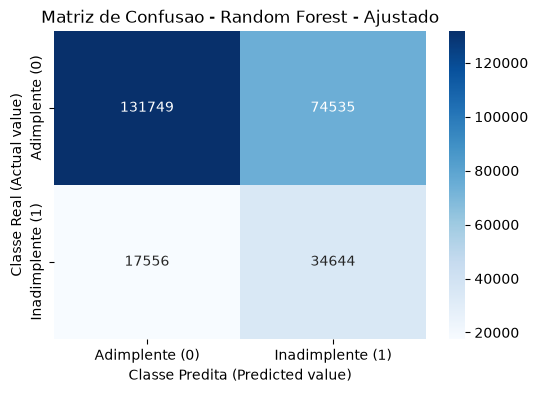

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf_tuned_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=12,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

rf_tuned_model.fit(X_train, y_train)

y_pred_val_rf_tuned = rf_tuned_model.predict(X_val)
y_pred_proba_val_rf_tuned = rf_tuned_model.predict_proba(X_val)[:, 1]

rf_tuned_params = {
    parametro: rf_tuned_model.get_params()[parametro]
    for parametro in [
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "class_weight",
        "random_state",
    ]
}

rf_tuned_results = evaluate_classification(
    y_val,
    y_pred_val_rf_tuned,
    y_pred_proba_val_rf_tuned,
    model_name="Random Forest - Ajustado",
)

## 4. XGBoost

O XGBoost é um algoritmo de *ensemble learning* baseado no treinamento sequencial de árvores de decisão. A cada etapa, o modelo busca corrigir os erros cometidos pelas árvores anteriores, permitindo representar relações não lineares complexas.

Assim como nos modelos anteriores, o XGBoost será treinado com os dados de treino e avaliado na validação. Para lidar com o desbalanceamento da variável alvo, será utilizado `scale_pos_weight`, calculado a partir da proporção entre as classes do conjunto de treino.

--- Resultados: XGBoost - Baseline ---
PR-AUC  : 0.3861
F1-score: 0.4325
Recall  : 0.6712
Precisao: 0.3191
Acuracia: 0.6443



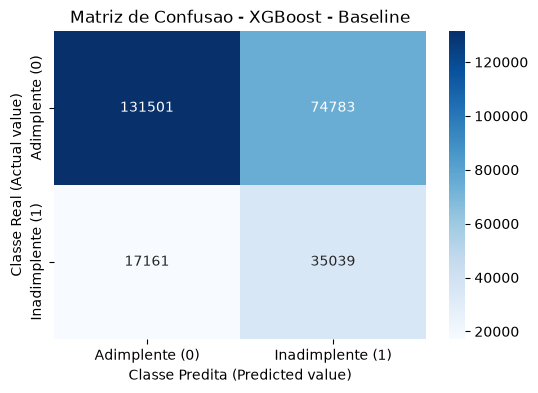

In [12]:
from xgboost import XGBClassifier

# Calcula o peso da classe de inadimplentes
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

y_pred_val_xgb = xgb_model.predict(X_val)
y_pred_proba_val_xgb = xgb_model.predict_proba(X_val)[:, 1]

xgb_params = {
    parametro: xgb_model.get_params()[parametro]
    for parametro in [
        "n_estimators",
        "max_depth",
        "learning_rate",
        "scale_pos_weight",
        "random_state",
    ]
}

xgb_results = evaluate_classification(
    y_val,
    y_pred_val_xgb,
    y_pred_proba_val_xgb,
    model_name="XGBoost - Baseline",
)

### 4.1. Ajuste de Hiperparâmetros

Após o treinamento inicial, serão testadas algumas combinações de `n_estimators`, `max_depth` e `learning_rate`. A comparação será feita no conjunto de validação, priorizando PR-AUC, F1-score e Recall. O conjunto OOT será utilizado somente na avaliação final.

In [5]:
from sklearn.model_selection import ParameterGrid

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],           
    "learning_rate": [0.05, 0.1]      
}

xgb_tuning_results = []

for params in ParameterGrid(xgb_param_grid):
    model = XGBClassifier(
        **params,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    xgb_tuning_results.append({
        **params,
        "PR-AUC": average_precision_score(y_val, y_proba),
        "F1-score": f1_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
    })

xgb_tuning_results_df = (
    pd.DataFrame(xgb_tuning_results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

xgb_tuning_results_df

,learning_rate,max_depth,n_estimators,PR-AUC,F1-score,Recall
0,0.05,7,300,0.388081,0.434131,0.667950
1,0.10,5,300,0.387837,0.433954,0.671839
2,0.10,7,300,0.387223,0.434252,0.662663
3,0.10,7,200,0.387215,0.434243,0.666226
4,0.10,5,200,0.387023,0.433630,0.673161
5,0.05,7,200,0.387019,0.433390,0.669617
6,0.05,5,300,0.386327,0.433252,0.672931
7,0.10,7,100,0.386208,0.432908,0.669808
8,0.05,5,200,0.385040,0.432262,0.671667
9,0.05,7,100,0.384912,0.431198,0.668448


### 4.2. Treinamento da Melhor Configuração

A configuração com maior PR-AUC na validação será utilizada para treinar o XGBoost ajustado. O modelo será avaliado novamente na validação antes da comparação final com os demais algoritmos.

--- Resultados: XGBoost - Ajustado ---
PR-AUC  : 0.3881
F1-score: 0.4341
Recall  : 0.6680
Precisao: 0.3216
Acuracia: 0.6484



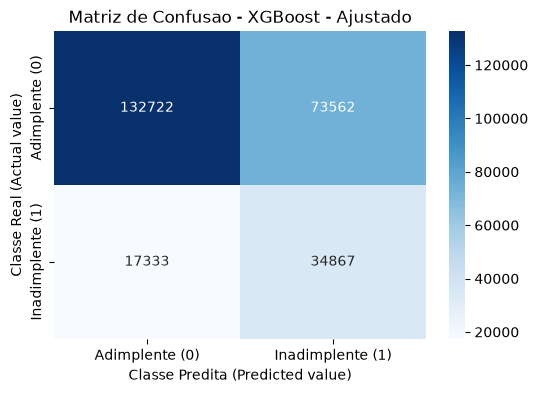

In [13]:
from xgboost import XGBClassifier

xgb_tuned_model = XGBClassifier(
    n_estimators=300,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

xgb_tuned_model.fit(X_train, y_train)

y_pred_val_xgb_tuned = xgb_tuned_model.predict(X_val)
y_pred_proba_val_xgb_tuned = xgb_tuned_model.predict_proba(X_val)[:, 1]

xgb_tuned_params = {
    parametro: xgb_tuned_model.get_params()[parametro]
    for parametro in [
        "n_estimators",
        "max_depth",
        "learning_rate",
        "scale_pos_weight",
        "random_state",
    ]
}

xgb_tuned_results = evaluate_classification(
    y_val,
    y_pred_val_xgb_tuned,
    y_pred_proba_val_xgb_tuned,
    model_name="XGBoost - Ajustado",
)

## 5. Registro e Comparação dos Modelos

Nesta etapa, são reunidos os resultados obtidos pelos modelos durante o desenvolvimento, utilizando exclusivamente o conjunto de validação. O objetivo é comparar o desempenho da Regressão Logística, utilizada como modelo baseline, com as versões inicial e ajustada do Random Forest e do XGBoost.

As métricas consideradas são PR-AUC, F1-score, Recall, precisão e acurácia. Essa comparação orienta a seleção dos modelos que serão submetidos à avaliação final no conjunto de teste Out-of-Time (OOT).

O conjunto OOT permanece isolado nesta etapa e não é utilizado para escolher modelos ou hiperparâmetros.

In [12]:
# Comparacao dos resultados obtidos no conjunto de validacao
comparison = pd.DataFrame([
    baseline_lr_results,
    baseline_rf_results,
    rf_tuned_results,
    xgb_results,
    xgb_tuned_results,
])

comparison

,Modelo,PR-AUC,F1-score,Recall,Precisao,Acuracia
0,Regressao Logistica - Baseline,0.374280,0.426769,0.652490,0.317079,0.646021
1,Random Forest - Baseline,0.380160,0.428064,0.672548,0.313940,0.637065
2,Random Forest - Ajustado,0.382337,0.429350,0.663678,0.317314,0.643726
3,XGBoost - Baseline,0.386082,0.432522,0.671245,0.319053,0.644295
4,XGBoost - Ajustado,0.388081,0.434131,0.667950,0.321565,0.648353


## 6. Calibração do Limiar de Decisão

Com os modelos ajustados, o limiar de decisão ótimo é calibrado exclusivamente
no conjunto de validação, mantendo o conjunto *Out-of-Time* completamente isolado
para a avaliação final.

Pela teoria de *Cost-Sensitive Learning* de Elkan (2001), o limiar ótimo $p^*$
é definido como:

$$p^* = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

A tabela abaixo apresenta os resultados para cada limiar testado. O limiar
selecionado será aquele que melhor equilibra Recall e F1-score no contexto
de predição de inadimplência.

In [24]:
from sklearn.metrics import f1_score, recall_score, precision_score
import pandas as pd

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

modelos_val = {
    "Regressão Logística": y_pred_proba_val_lr,
    "Random Forest":       y_pred_proba_val_rf_tuned,
    "XGBoost":             y_pred_proba_val_xgb_tuned,
}

calibration_results = []

for model_name, y_proba in modelos_val.items():
    for t in thresholds:
        y_pred_custom = (y_proba >= t).astype(int)
        calibration_results.append({
            "Modelo":    model_name,
            "Limiar":    t,
            "F1-score":  round(f1_score(y_val, y_pred_custom), 4),
            "Recall":    round(recall_score(y_val, y_pred_custom), 4),
            "Precisão":  round(precision_score(y_val, y_pred_custom), 4),
        })

calibration_df = (
    pd.DataFrame(calibration_results)
    .sort_values(["Modelo", "Limiar"])
    .reset_index(drop=True)
)

print("=== Calibração de Limiar - Conjunto de Validação ===")
display(calibration_df)

=== Calibração de Limiar - Conjunto de Validação ===


,Modelo,Limiar,F1-score,Recall,Precisão
0,Random Forest,0.30,0.3804,0.9358,0.2387
1,Random Forest,0.35,0.3962,0.8923,0.2546
2,Random Forest,0.40,0.4128,0.8302,0.2747
3,Random Forest,0.45,0.4239,0.7545,0.2947
4,Random Forest,0.50,0.4293,0.6637,0.3173
5,Regressão Logística,0.30,0.3808,0.9325,0.2393
6,Regressão Logística,0.35,0.3941,0.8880,0.2532
7,Regressão Logística,0.40,0.4089,0.8257,0.2718
8,Regressão Logística,0.45,0.4213,0.7445,0.2937
9,Regressão Logística,0.50,0.4268,0.6525,0.3171
